In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

# Project paths
PROJECT_DIR = Path.cwd().parent
DATA_FILE = PROJECT_DIR / "data" / "pm25_forecasting_dataset.csv"

# Load forecasting dataset
eda_df = pd.read_csv(DATA_FILE)

# Parse timestamps
eda_df["observed_at_ist"] = pd.to_datetime(
    eda_df["observed_at_ist"]
)

print("Dataset loaded successfully!")
print("Shape:", eda_df.shape)
print("Stations:", eda_df["station_name"].nunique())
print(
    "Date range:",
    eda_df["observed_at_ist"].min(),
    "to",
    eda_df["observed_at_ist"].max()
)

display(eda_df.head())

Dataset loaded successfully!
Shape: (197697, 41)
Stations: 13
Date range: 2025-02-19 01:00:00+05:30 to 2026-11-14 17:00:00+05:30


,observed_at_ist,observed_at,location_id,station_name,candidate_station,region,latitude,longitude,co,no,...,wind_speed_missing,wind_direction_sin,wind_direction_cos,PM25_next_1h,PM25_next_3h,available_aqi_pollutants,pm25_24h_avg,pm25_aqi_category,target_1h,target_3h
0,2025-02-19 01:00:00+05:30,2025-02-18 19:30:00+00:00,6932,"Alipur, Delhi - DPCC",Alipur,North Delhi,28.815329,77.15301,0.150,5.0,...,0,-0.766044,-0.642788,59.8,146.0,6,NaN,NaN,NaN,NaN
1,2025-02-19 02:00:00+05:30,2025-02-18 20:30:00+00:00,6932,"Alipur, Delhi - DPCC",Alipur,North Delhi,28.815329,77.15301,0.350,16.3,...,0,-0.719340,-0.694658,82.0,205.0,6,NaN,NaN,NaN,NaN
2,2025-02-19 03:00:00+05:30,2025-02-18 21:30:00+00:00,6932,"Alipur, Delhi - DPCC",Alipur,North Delhi,28.815329,77.15301,0.645,23.5,...,0,-0.309017,-0.951057,146.0,174.0,6,NaN,NaN,NaN,NaN
3,2025-02-19 04:00:00+05:30,2025-02-18 22:30:00+00:00,6932,"Alipur, Delhi - DPCC",Alipur,North Delhi,28.815329,77.15301,0.588,12.7,...,0,-0.544639,-0.838671,205.0,128.0,6,NaN,NaN,NaN,NaN
4,2025-02-19 05:00:00+05:30,2025-02-18 23:30:00+00:00,6932,"Alipur, Delhi - DPCC",Alipur,North Delhi,28.815329,77.15301,0.563,11.5,...,0,-0.809017,-0.587785,174.0,119.0,6,NaN,NaN,NaN,NaN


In [2]:
# Separate column groups
print("ALL COLUMNS:")
for i, col in enumerate(eda_df.columns, 1):
    print(f"{i:2}. {col}")

print("\nDATA TYPES:")
display(eda_df.dtypes.to_frame("Data Type"))

print("\nNUMERICAL SUMMARY:")
display(eda_df.describe().T)

ALL COLUMNS:
 1. observed_at_ist
 2. observed_at
 3. location_id
 4. station_name
 5. candidate_station
 6. region
 7. latitude
 8. longitude
 9. co
10. no
11. no2
12. nox
13. o3
14. pm10
15. pm25
16. relative_humidity
17. so2
18. temperature
19. wind_direction
20. wind_speed
21. PM25_Missing
22. co_missing
23. no_missing
24. no2_missing
25. nox_missing
26. o3_missing
27. pm10_missing
28. relative_humidity_missing
29. so2_missing
30. temperature_missing
31. wind_direction_missing
32. wind_speed_missing
33. wind_direction_sin
34. wind_direction_cos
35. PM25_next_1h
36. PM25_next_3h
37. available_aqi_pollutants
38. pm25_24h_avg
39. pm25_aqi_category
40. target_1h
41. target_3h

DATA TYPES:


,Data Type
observed_at_ist,"datetime64[us, UTC+05:30]"
observed_at,str
location_id,int64
station_name,str
candidate_station,str
region,str
latitude,float64
longitude,float64
co,float64
no,float64



NUMERICAL SUMMARY:


,count,mean,std,min,25%,50%,75%,max
location_id,197697.0,5859.958027,3482.842468,17.000000,5613.000000,6931.000000,6960.000000,10831.000000
latitude,197697.0,28.666509,0.070167,28.563262,28.628624,28.646835,28.684678,28.815329
longitude,197697.0,77.176717,0.087378,77.051074,77.119920,77.153010,77.241060,77.316032
co,176381.0,1.224549,0.969325,0.000000,0.673000,0.980000,1.450000,9.840000
no,177328.0,21.116391,40.553268,0.000000,3.300000,6.980000,20.300000,499.000000
no2,164002.0,40.868863,29.951944,0.000000,19.300000,33.600000,55.200000,445.000000
nox,177978.0,0.039298,0.044620,0.000000,0.014200,0.025200,0.047200,1.940000
o3,164671.0,29.426033,33.229735,0.000000,7.630000,17.000000,38.600000,491.000000
pm10,176608.0,197.807638,140.296175,0.000000,99.000000,163.000000,259.000000,1790.000000
pm25,176475.0,88.759722,87.325564,0.000000,33.300000,57.500000,112.000000,997.000000


,Count,Percentage
pm25_aqi_category,,
Good,25099,14.18
Satisfactory,60098,33.95
Moderate,34446,19.46
Poor,18700,10.56
Very Poor,28322,16.00
Severe,10352,5.85


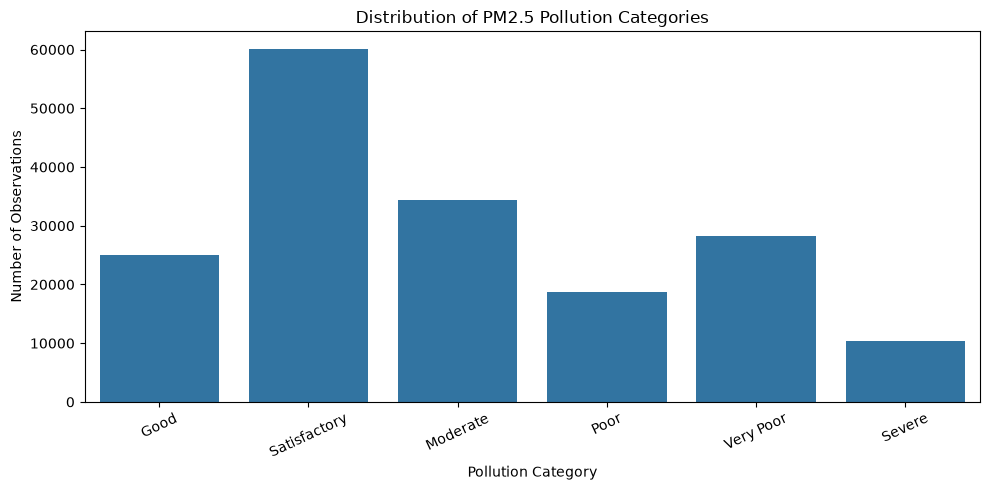

In [3]:
# Define the correct category order
category_order = [
    "Good",
    "Satisfactory",
    "Moderate",
    "Poor",
    "Very Poor",
    "Severe"
]

# Count observations in each category
category_counts = (
    eda_df["pm25_aqi_category"]
    .value_counts()
    .reindex(category_order)
)

# Calculate percentages
category_percentages = (
    category_counts / category_counts.sum() * 100
)

category_summary = pd.DataFrame({
    "Count": category_counts,
    "Percentage": category_percentages.round(2)
})

display(category_summary)

# Plot category distribution
plt.figure(figsize=(10, 5))

sns.barplot(
    x=category_summary.index,
    y=category_summary["Count"]
)

plt.title("Distribution of PM2.5 Pollution Categories")
plt.xlabel("Pollution Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

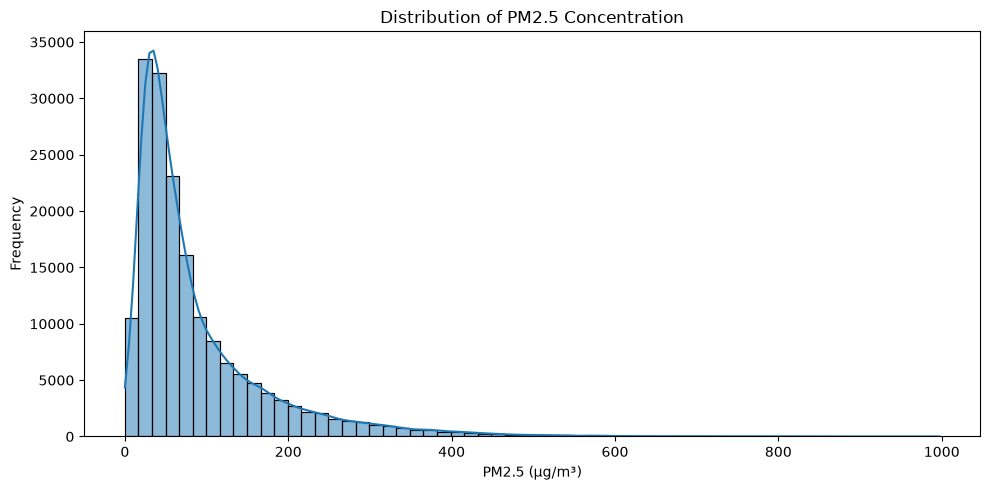

In [4]:
# PM2.5 distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="pm25",
    bins=60,
    kde=True
)

plt.title("Distribution of PM2.5 Concentration")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

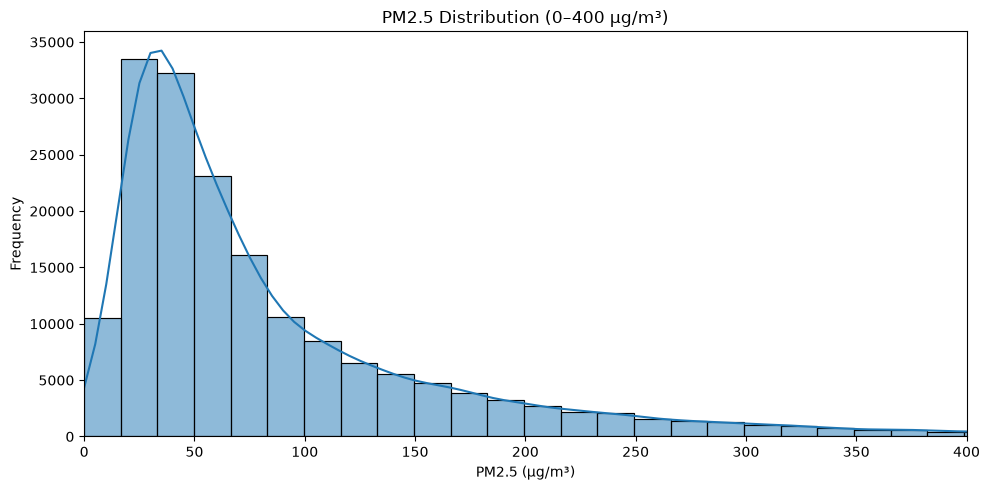

In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=eda_df,
    x="pm25",
    bins=60,
    kde=True
)

plt.xlim(0, 400)

plt.title("PM2.5 Distribution (0–400 µg/m³)")
plt.xlabel("PM2.5 (µg/m³)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

,count,mean,median,std,min,max
candidate_station,,,,,,
Bawana,13621,103.36,68.8,95.61,1.0,920.0
Anand Vihar,13493,100.12,69.5,91.49,1.0,767.0
Rohini,13910,98.16,60.3,98.42,1.0,690.0
Mundka,13744,94.16,55.8,96.57,1.0,857.0
RK Puram,13489,92.09,61.3,88.11,1.0,924.0
Punjabi Bagh,13386,91.94,59.0,91.68,1.0,993.0
Vivek Vihar,13549,91.80,54.0,96.46,1.0,873.0
Alipur,13323,85.57,57.3,79.32,1.0,759.0
Dwarka,13750,83.00,54.3,78.44,1.0,774.0


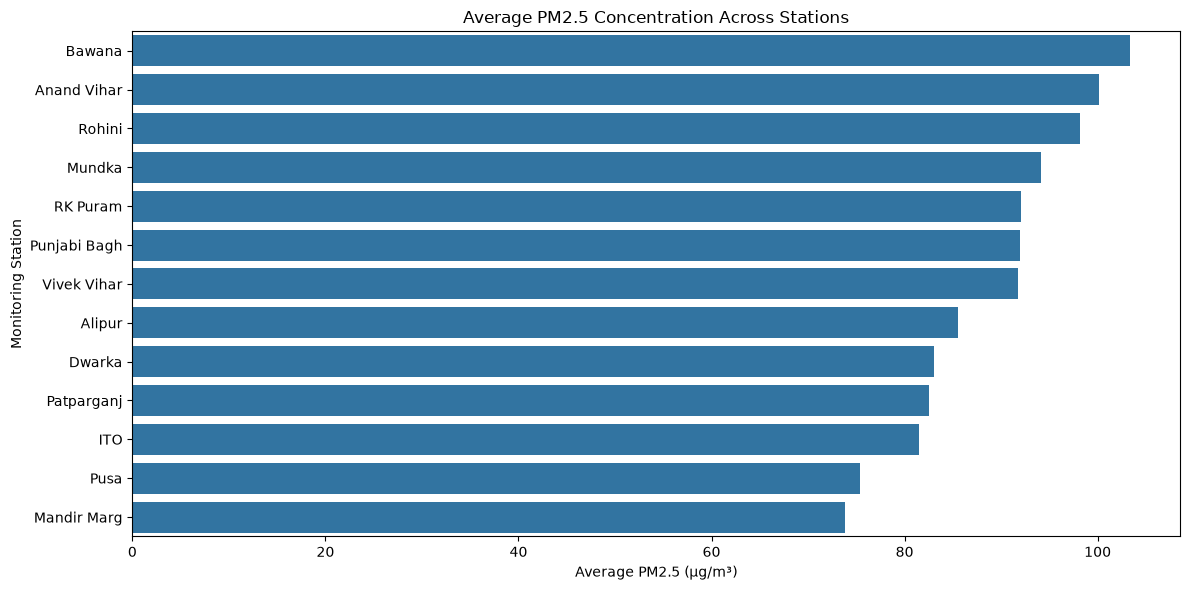

In [6]:
# Station-wise PM2.5 statistics
station_pm25 = (
    eda_df.groupby("candidate_station")["pm25"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .sort_values("mean", ascending=False)
)

display(station_pm25.round(2))

# Visualize average PM2.5 by station
plt.figure(figsize=(12, 6))

sns.barplot(
    data=station_pm25.reset_index(),
    x="mean",
    y="candidate_station"
)

plt.title("Average PM2.5 Concentration Across Stations")
plt.xlabel("Average PM2.5 (µg/m³)")
plt.ylabel("Monitoring Station")
plt.tight_layout()
plt.show()

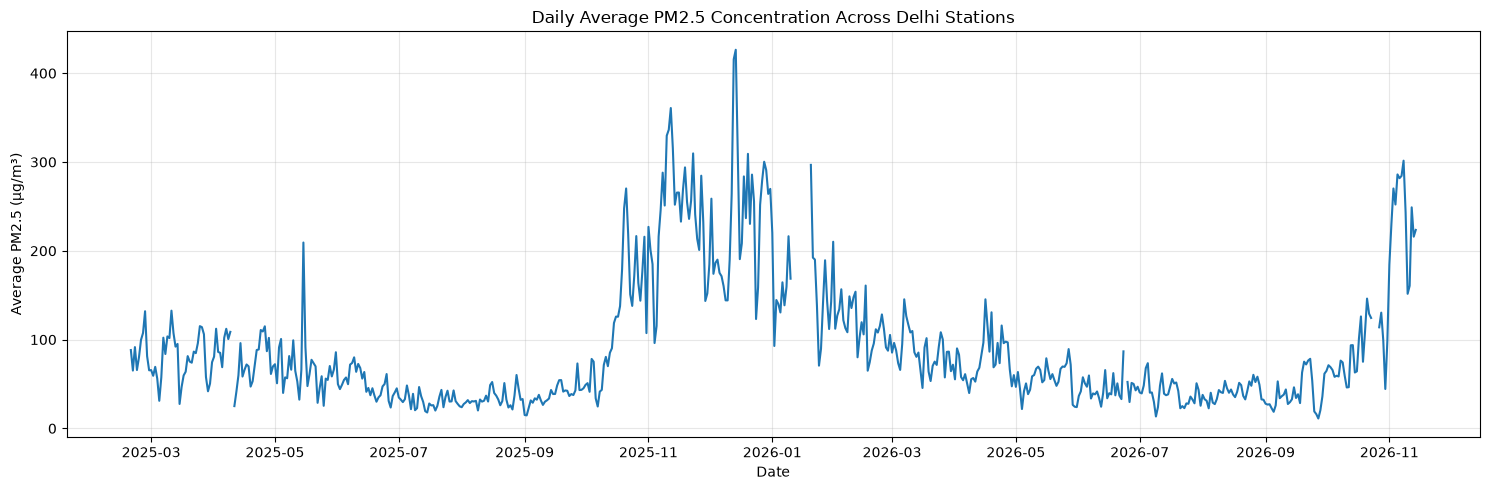

In [7]:
# Daily average PM2.5 across all stations
daily_pm25 = (
    eda_df.set_index("observed_at_ist")["pm25"]
    .resample("D")
    .mean()
)

plt.figure(figsize=(15, 5))

plt.plot(daily_pm25.index, daily_pm25.values)

plt.title("Daily Average PM2.5 Concentration Across Delhi Stations")
plt.xlabel("Date")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

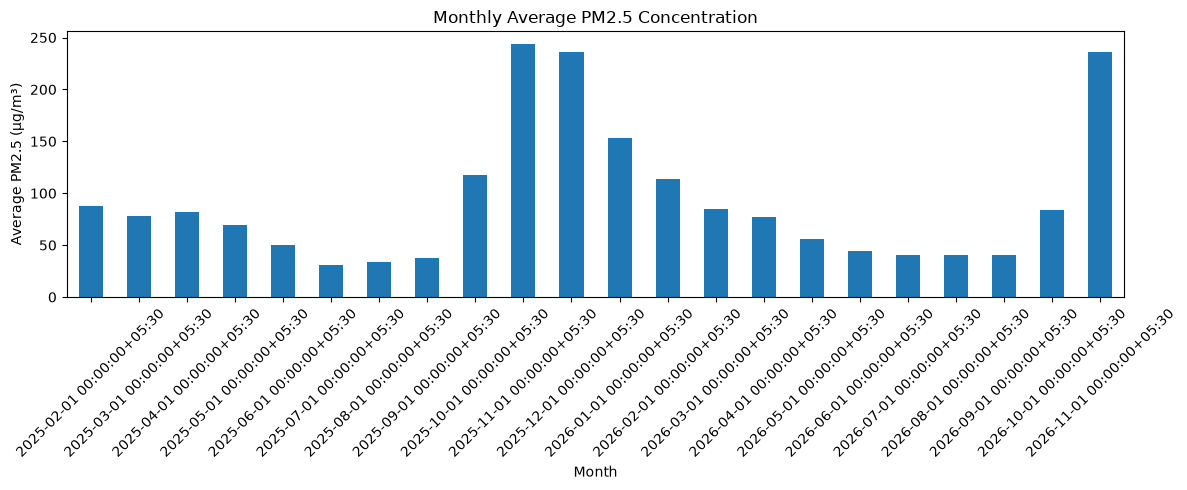

In [8]:
monthly_pm25 = (
    eda_df.set_index("observed_at_ist")["pm25"]
    .resample("MS")
    .mean()
)

plt.figure(figsize=(12, 5))
monthly_pm25.plot(kind="bar")
plt.title("Monthly Average PM2.5 Concentration")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

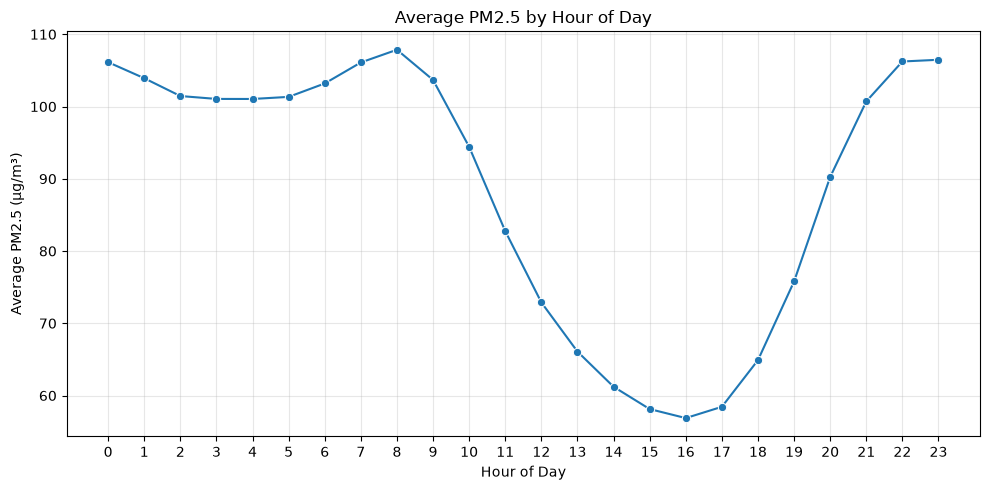

In [9]:
eda_df["hour"] = eda_df["observed_at_ist"].dt.hour

hourly_pm25 = eda_df.groupby("hour")["pm25"].mean()

plt.figure(figsize=(10, 5))
sns.lineplot(x=hourly_pm25.index, y=hourly_pm25.values, marker="o")
plt.title("Average PM2.5 by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

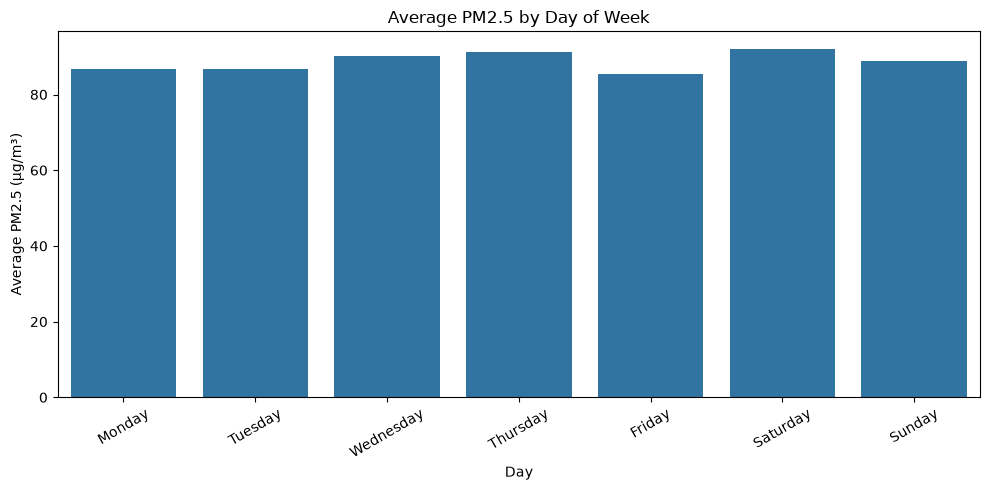

In [10]:
eda_df["day_of_week"] = eda_df["observed_at_ist"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_pm25 = (
    eda_df.groupby("day_of_week")["pm25"]
    .mean()
    .reindex(day_order)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=weekday_pm25.index, y=weekday_pm25.values)
plt.title("Average PM2.5 by Day of Week")
plt.xlabel("Day")
plt.ylabel("Average PM2.5 (µg/m³)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

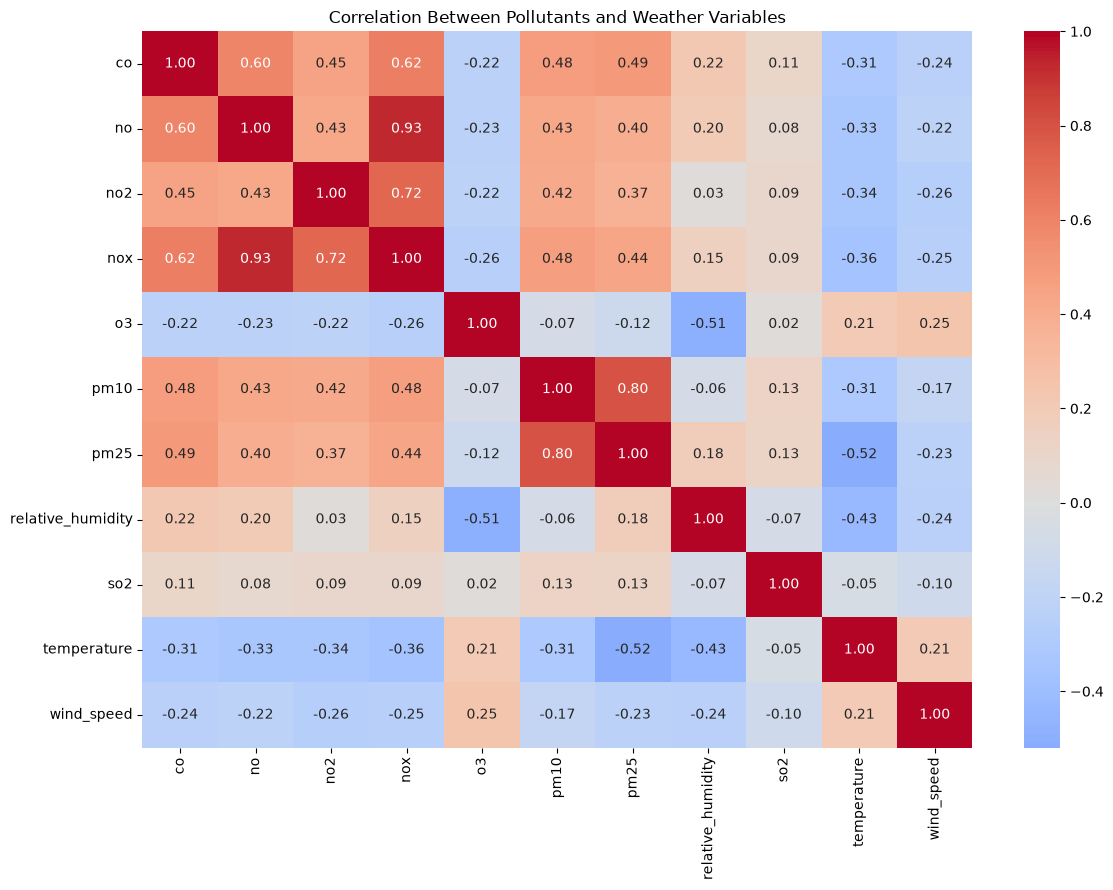

In [11]:
correlation_cols = [
    "co", "no", "no2", "nox", "o3",
    "pm10", "pm25", "relative_humidity",
    "so2", "temperature", "wind_speed"
]

correlation_matrix = eda_df[correlation_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlation Between Pollutants and Weather Variables")
plt.tight_layout()
plt.show()

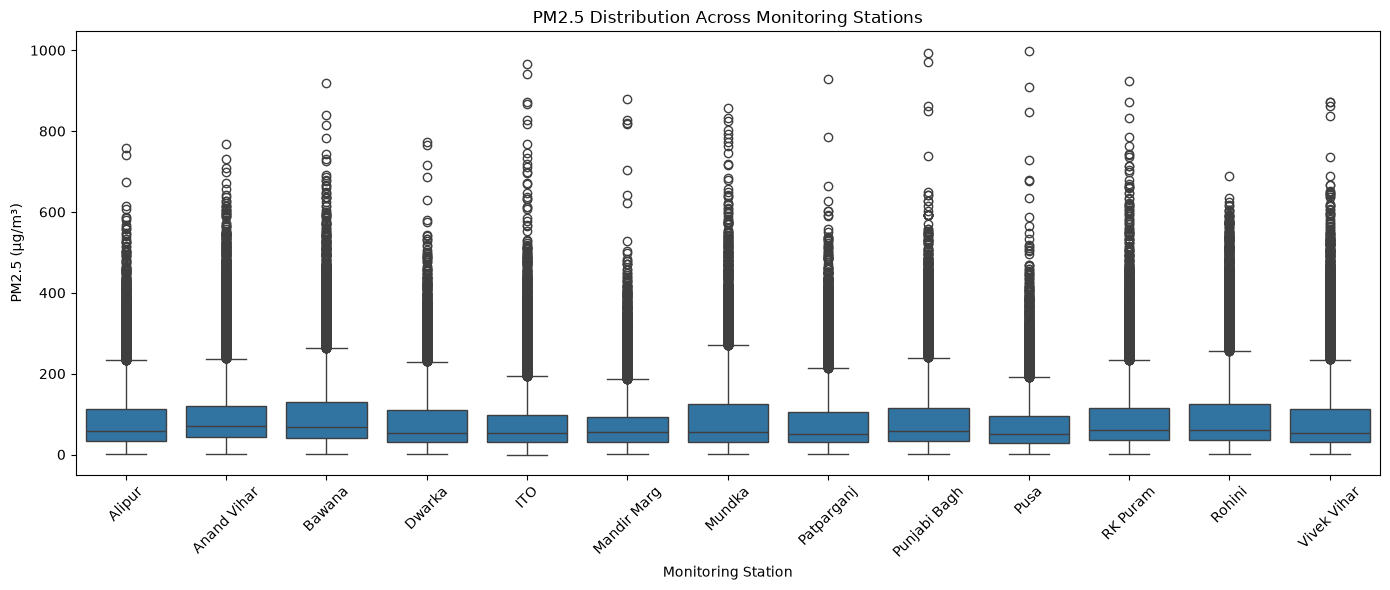

In [12]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=eda_df,
    x="candidate_station",
    y="pm25"
)

plt.title("PM2.5 Distribution Across Monitoring Stations")
plt.xlabel("Monitoring Station")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

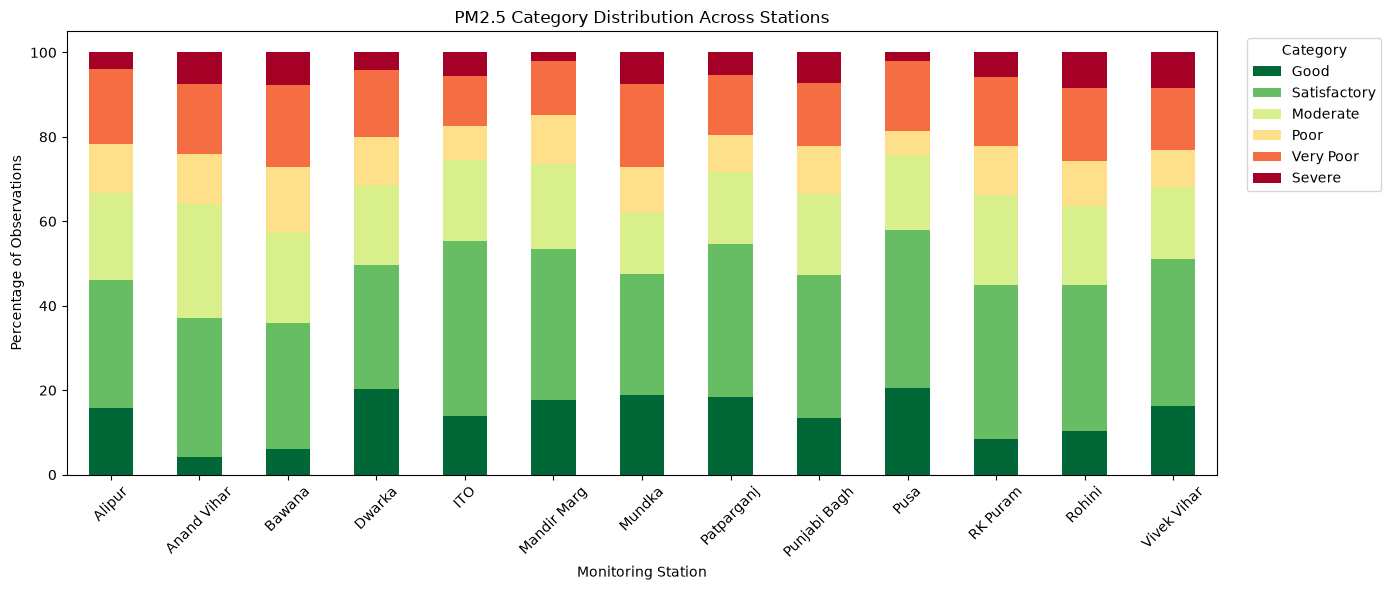

In [13]:
station_category = pd.crosstab(
    eda_df["candidate_station"],
    eda_df["pm25_aqi_category"],
    normalize="index"
) * 100

station_category = station_category[
    ["Good", "Satisfactory", "Moderate",
     "Poor", "Very Poor", "Severe"]
]

station_category.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 6),
    colormap="RdYlGn_r"
)

plt.title("PM2.5 Category Distribution Across Stations")
plt.xlabel("Monitoring Station")
plt.ylabel("Percentage of Observations")
plt.legend(title="Category", bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

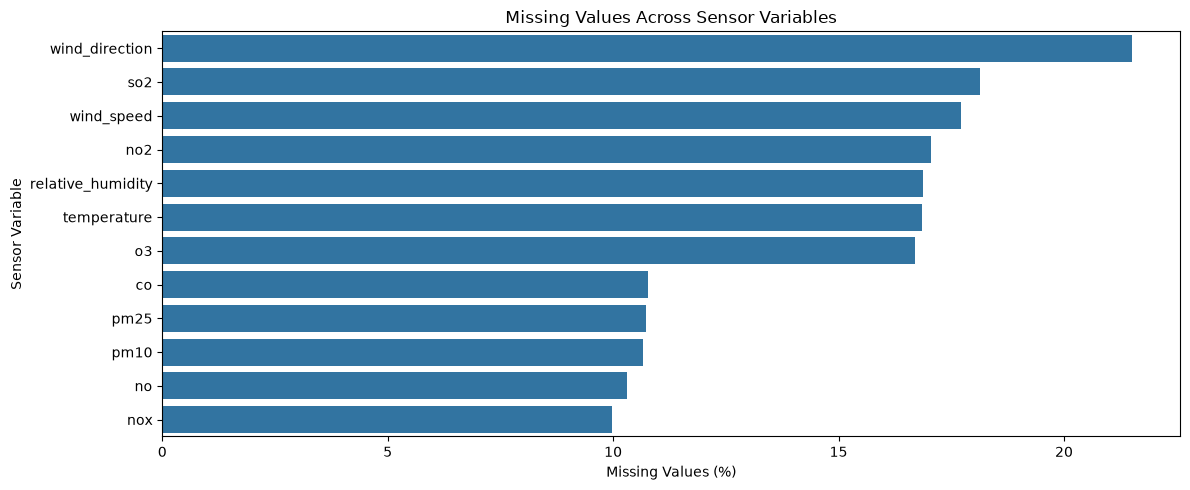

In [14]:
sensor_cols = [
    "co", "no", "no2", "nox", "o3",
    "pm10", "pm25", "relative_humidity",
    "so2", "temperature", "wind_direction",
    "wind_speed"
]

missing_percentage = (
    eda_df[sensor_cols].isna().mean() * 100
).sort_values(ascending=False)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=missing_percentage.values,
    y=missing_percentage.index
)

plt.title("Missing Values Across Sensor Variables")
plt.xlabel("Missing Values (%)")
plt.ylabel("Sensor Variable")
plt.tight_layout()
plt.show()

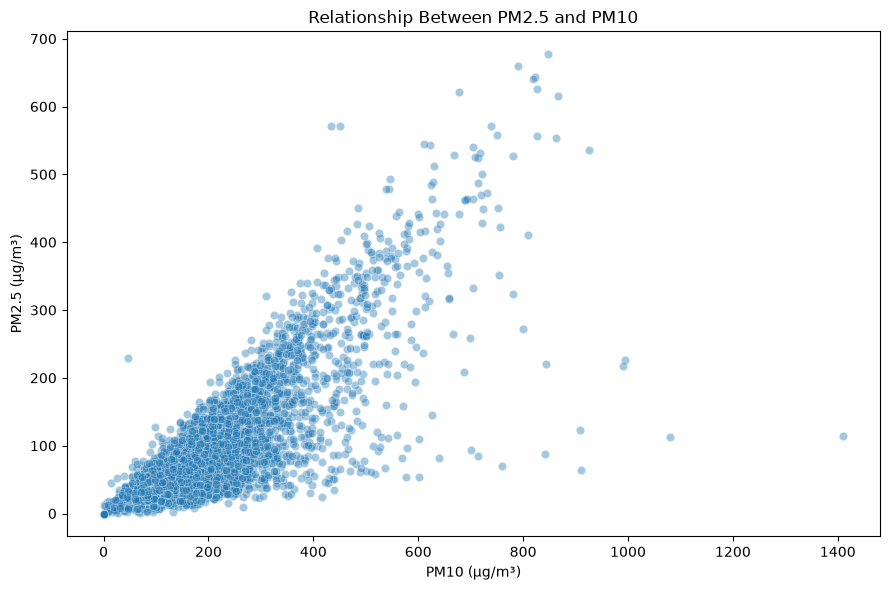

In [15]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=eda_df.sample(
        n=min(5000, len(eda_df)),
        random_state=42
    ),
    x="pm10",
    y="pm25",
    alpha=0.4
)

plt.title("Relationship Between PM2.5 and PM10")
plt.xlabel("PM10 (µg/m³)")
plt.ylabel("PM2.5 (µg/m³)")
plt.tight_layout()
plt.show()